In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Introducción Datos MNIST


In [3]:
from sklearn.datasets import fetch_openml
# Cargar el dataset MNISTcamp
print("Cargando el dataset MNIST...")
X, y = fetch_openml('mnist_784', version=1, return_X_y=True, as_frame=False, parser='auto')
y = y.astype(int)  # Convertir las etiquetas a enteros


Cargando el dataset MNIST...


# Mostramos por pantalla un dato de ejemplo

In [4]:
# Filtrar imágenes que corresponden a la etiqueta '1'
mask = (y == 1)
X_1 = X[mask]


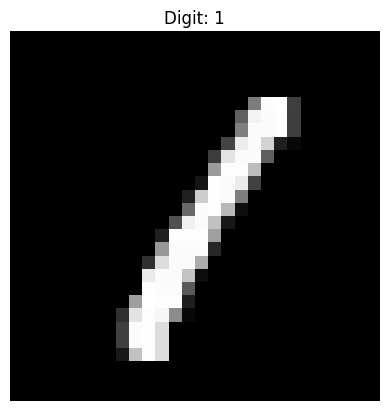

In [5]:
# Seleccionar la primera imagen de las filtradas y cambiar su forma a 28x28 para la visualización
image = X_1[0].reshape(28, 28)  # Cambiar la forma para visualización

# Visualizar la imagen
plt.imshow(image, cmap='gray')  # Usar un mapa de colores en escala de grises
plt.title('Digit: 1')
plt.axis('off')  # Esconder los ejes para una mejor visualización
plt.show()

In [6]:
X_1.shape

#Tenemos 7877 ejemplos de 784 dimensiones cada uno.

(7877, 784)

In [9]:
X

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(70000, 784))

# Representación Gráfica

In [10]:
# Normalizar los valores de los píxeles (de 0-255 a 0-1)
X = X / 255.0
# Tomar una submuestra aleatoria de 10,000 datos para acelerar los cálculos
n_samples = 10000
np.random.seed(42)
indices = np.random.choice(X.shape[0], n_samples, replace=False)

X_sub = X[indices]
y_sub = y[indices]

print(f"Datos preparados. Tamaño de la muestra: {X_sub.shape}")

Datos preparados. Tamaño de la muestra: (10000, 784)


## Proyección PCA

In [11]:
from sklearn.decomposition import PCA

Calculando PCA...


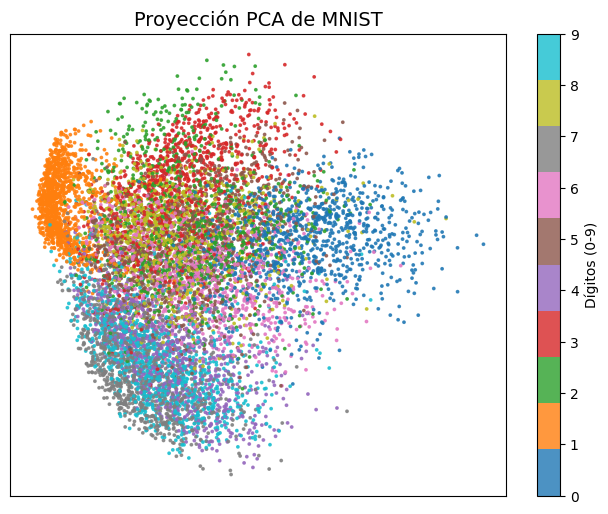

In [12]:
print("Calculando PCA...")
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_sub)

# Gráfico PCA
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_sub, cmap='tab10', s=3, alpha=0.8)

# Detalles
plt.colorbar(scatter, label='Dígitos (0-9)', ticks=range(10))
plt.title('Proyección PCA de MNIST', fontsize=14)
plt.xticks([])
plt.yticks([])
plt.show()

## Proyección T-SNE

In [13]:
from sklearn.manifold import TSNE

Calculando t-SNE...


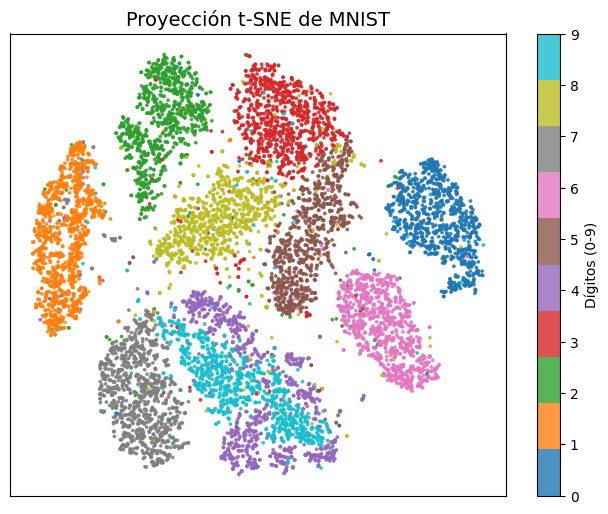

In [14]:
print("Calculando t-SNE...")
# Reducimos a 50 dimensiones primero para que t-SNE sea más rápido
pca_50 = PCA(n_components=50)
X_pca_50 = pca_50.fit_transform(X_sub)

tsne = TSNE(n_components=2, random_state=42, init='pca', learning_rate='auto')
X_tsne = tsne.fit_transform(X_pca_50)

# Gráfico t-SNE
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_sub, cmap='tab10', s=3, alpha=0.8)

# Detalles
plt.colorbar(scatter, label='Dígitos (0-9)', ticks=range(10))
plt.title('Proyección t-SNE de MNIST', fontsize=14)
plt.xticks([])
plt.yticks([])
plt.show()

## Proyección UMAP

In [15]:
import umap


Calculando UMAP...


c:\Users\Usuario\GitHub\ucm\venv_ucm\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


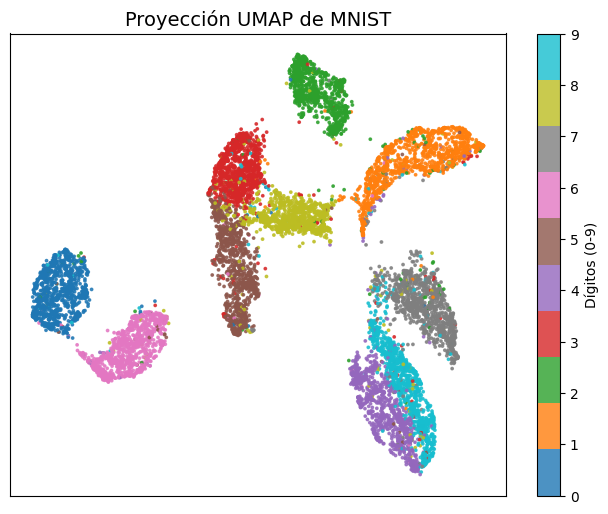

In [16]:
print("Calculando UMAP...")
umap_model = umap.UMAP(n_components=2, random_state=42)
X_umap = umap_model.fit_transform(X_sub)

# Gráfico UMAP
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_umap[:, 0], X_umap[:, 1], c=y_sub, cmap='tab10', s=3, alpha=0.8)

# Detalles
plt.colorbar(scatter, label='Dígitos (0-9)', ticks=range(10))
plt.title('Proyección UMAP de MNIST', fontsize=14)
plt.xticks([])
plt.yticks([])
plt.show()

# Modelo Naive Bayes

Procedimiento del Análisis Discriminante

1. Establecer un modelo para $p(x|y=c)$ para cada clase $c$. (Usaremos Naive Bayes con datos binarizados)
2. Estimar los parámetros $\theta_c$ de cada modelo mediante máxima verosimilitud.
3. Calcular la probabilidad a posteriori $p(y=c|x)$ usando el Teorema de Bayes.
4. Asignar las instancias que deseamos predecir a la clase que maximice la probabilidad posterior.


## Binarizamos los datos

In [18]:
from sklearn.model_selection import train_test_split
# Binarizar los datos: píxeles mayores que 127.5 se convierten en 1, de lo contrario en 0
X_binarized = np.where(X_sub > 0.5, 1, 0)

# Dividir el dataset en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X_binarized, y_sub, test_size=0.2, random_state=42)

In [19]:
# Otra fora
X_binarized_ = X > 127.5
X_binarized_[0].astype(int)


array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,